In [2]:
title = "# Introduction to Bayesian statistics: exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
#bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)
import numpy as np
import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Exercise 1

- Implement your own version of the line-fitting procedure, using the same data.
- Now try it with the data in `lectures/data/linear_fits/data_1.txt`
    - First plot the data. What has changed?
    - Try the same model and likelihood on the new data. You might want to adjust the prior on $m$ and $b$ for this new data set.
    - What if you use the provided uncertainty per data point $\sigma_{y_i}$, instead of assuming a constant variance $\sigma_y$ for all data points?
    - Instead use the actual likelihood of the data:
\begin{align}
    \mu(x) &= mx + b \\
    \sigma(x_i) &= \sigma_{y_i} + f\mu(x_i)^2 \quad f > 0\ \text{a parameter} \\
    y_i&\sim\mathcal N(\mu(x_i),\sigma(x_i)^2)
\end{align}
Careful with the normalisation of the Gaussian likelihood. Because we vary the variance, this matters now!

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

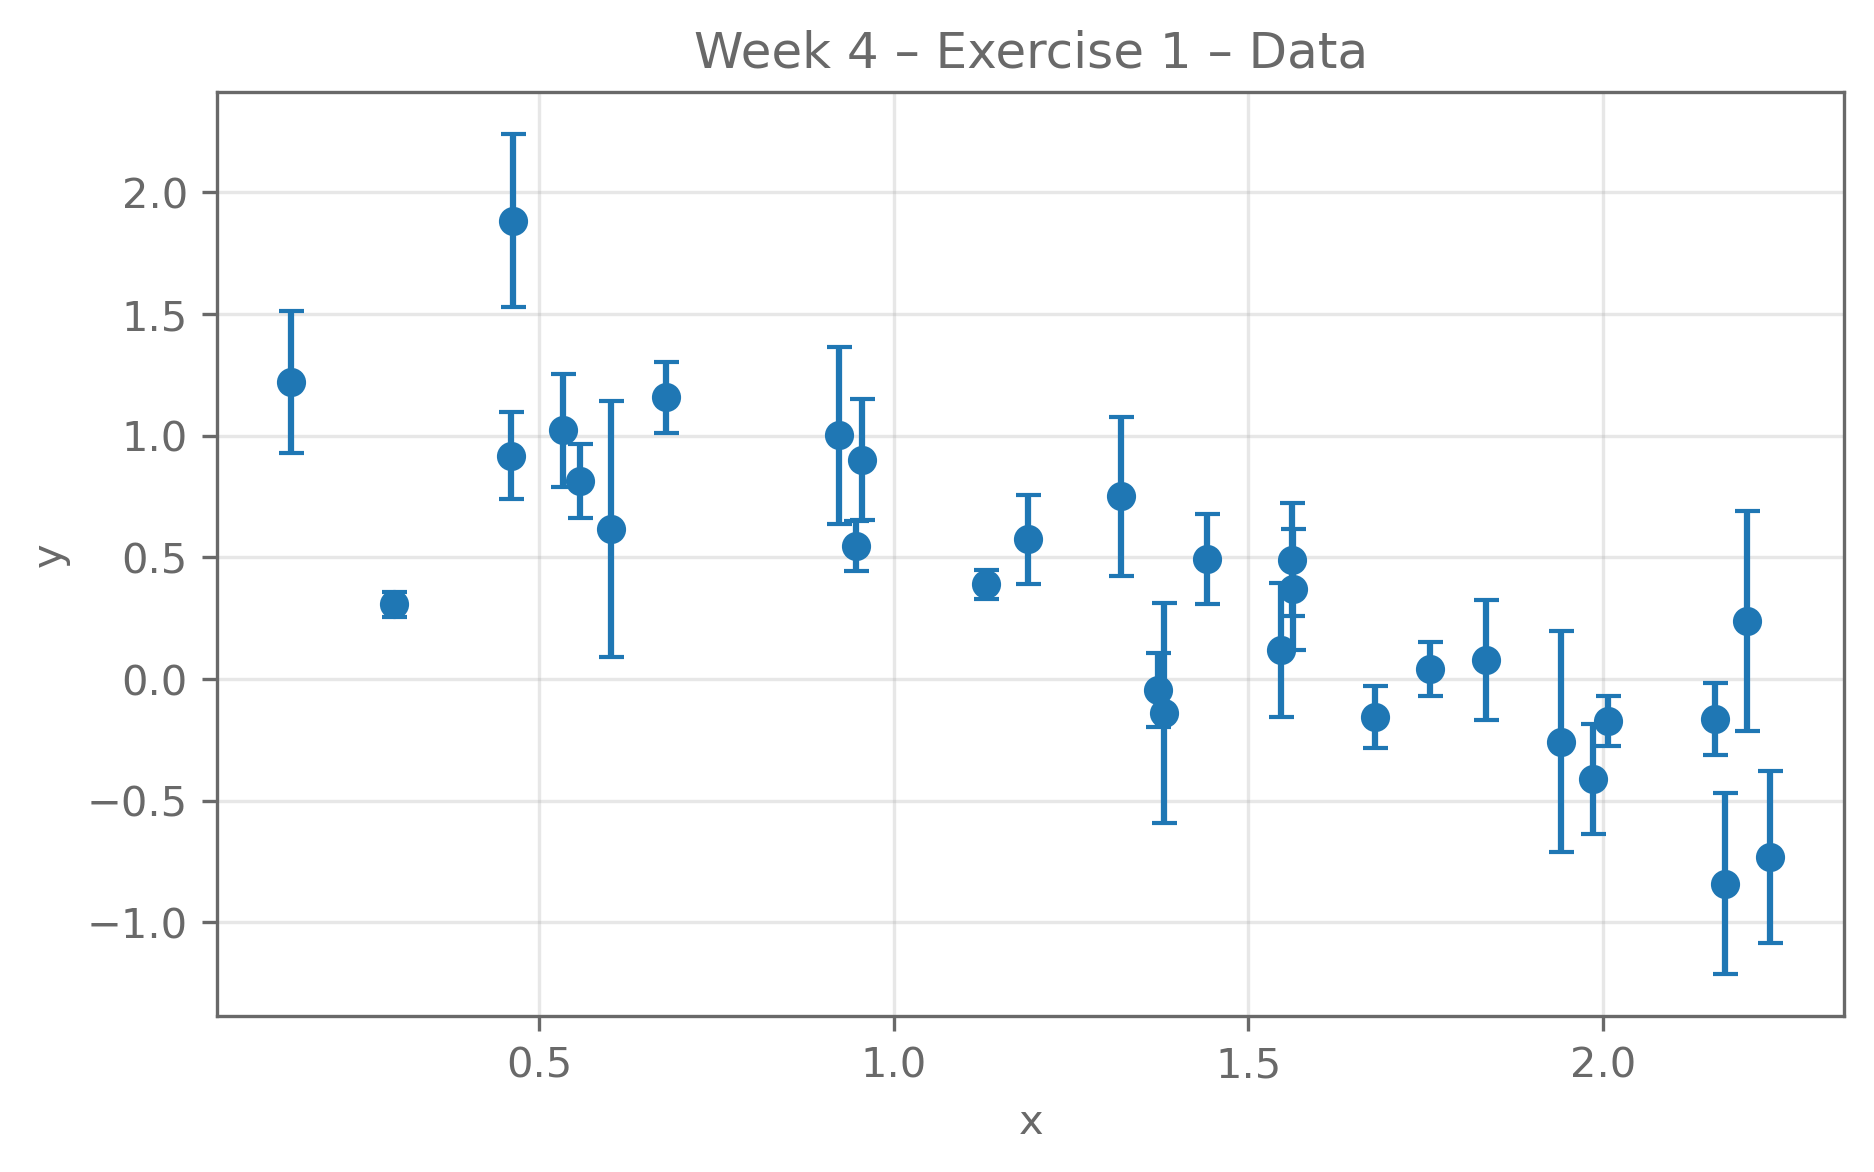

In [4]:
x1, y1, yerr1 = np.loadtxt(
    "../lectures/data/linear_fits/data_1.txt",
    unpack=True
)

plt.errorbar(x1, y1, yerr=yerr1, fmt='o', capsize=3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Week 4 – Exercise 1 – Data")
plt.grid(alpha=0.3)
plt.show()

MAP: [-0.39610133  0.73883538]
Posterior std: [0.0411028  0.05001865]


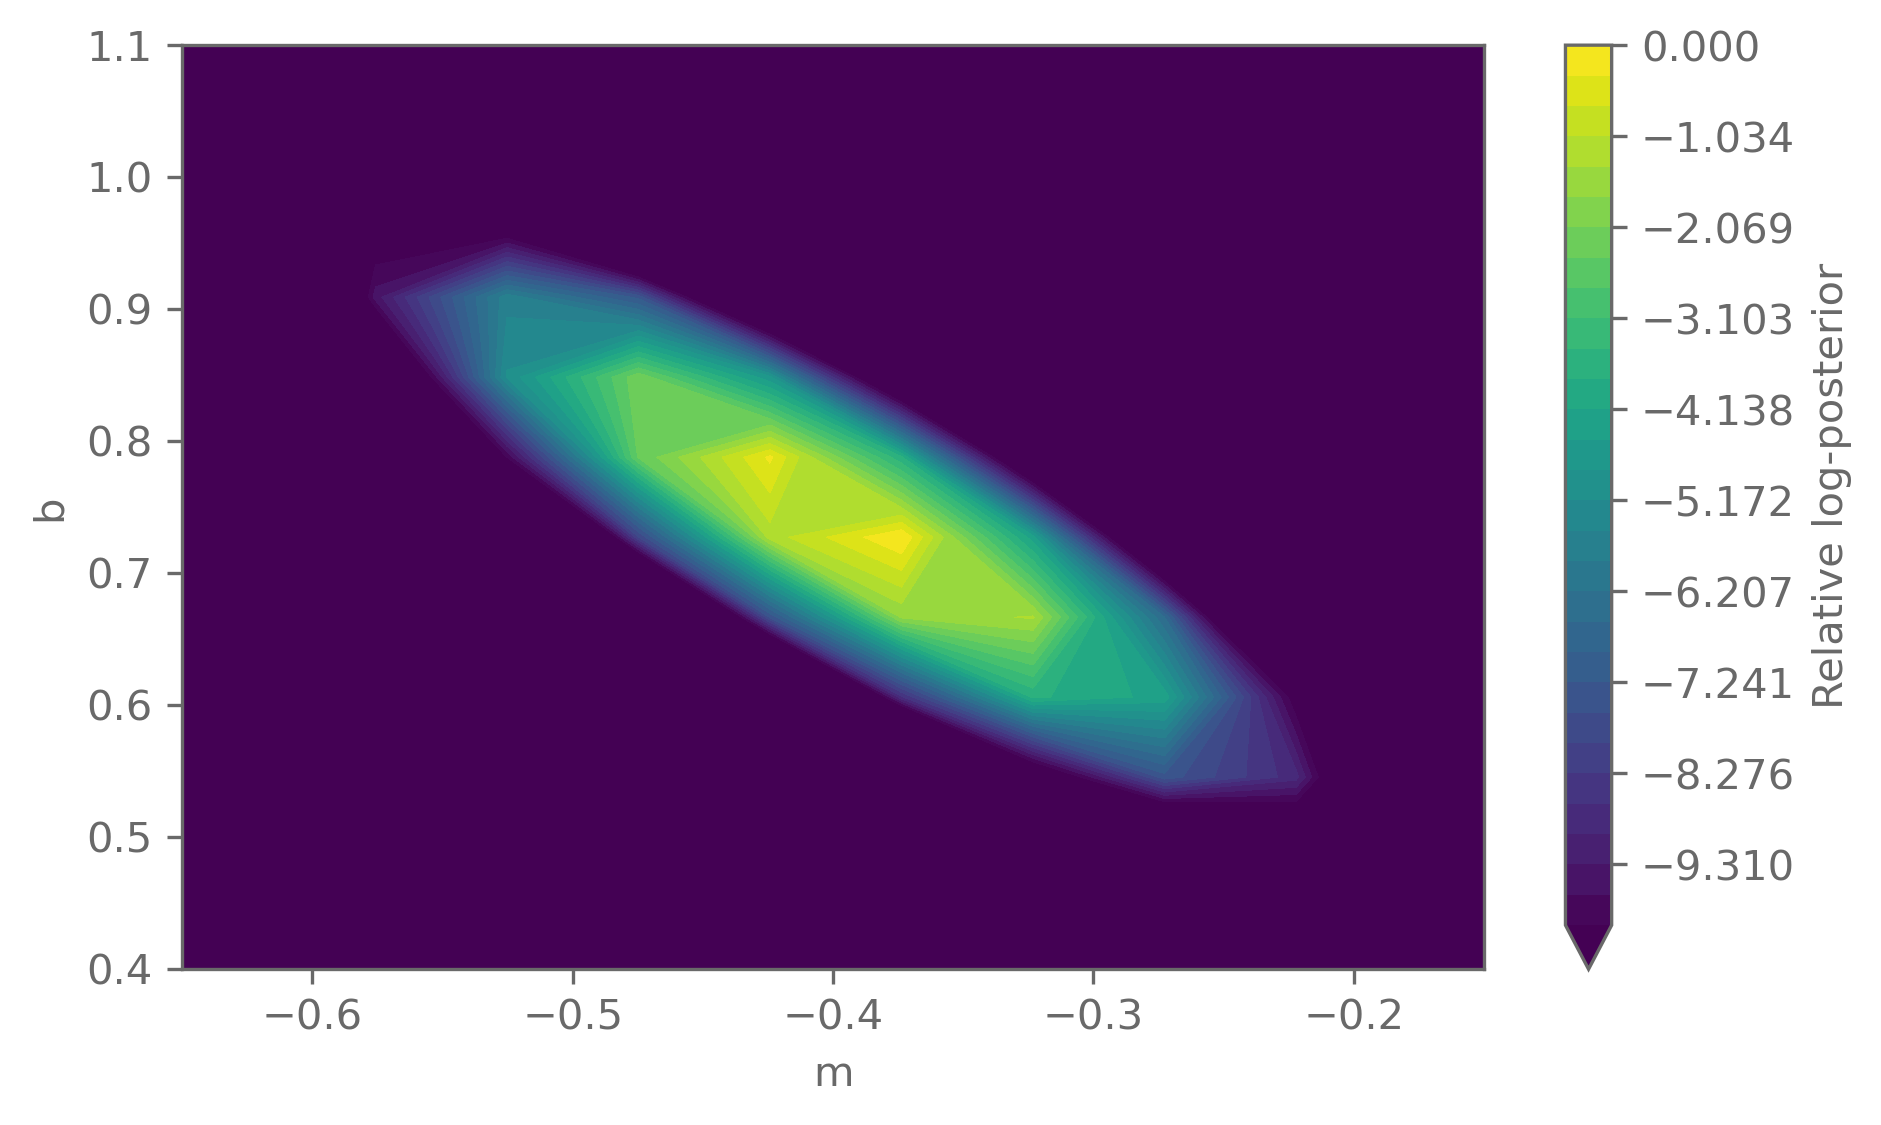

In [19]:
m_prior = norm(loc=-1, scale=0.2)
b_prior = norm(loc=2, scale=0.5)

def log_prior(m, b):
    return m_prior.logpdf(m) + b_prior.logpdf(b)

def linear_model(x, m, b):
    return m * x + b

def log_likelihood(m,b,x,y,sigma_y):
    return np.sum(-0.5 * np.log(2*np.pi) - np.log(sigma_y) - 0.5 * sigma_y**(-2) * (y-linear_model(x,m,b))**2)

def log_posterior(m, b, x, y, sigma_y):
    return log_likelihood(m,b,x,y,sigma_y) + log_prior(m,b)

m_grid = np.linspace(-3, 2, 100)
b_grid = np.linspace(-2, 4, 100)

M, B = np.meshgrid(m_grid, b_grid)

log_posterior_grid = np.empty_like(M)

sigma_y_const = 1

for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        log_posterior_grid[i, j] = log_posterior(M[i,j],B[i,j],x1,y1,yerr1)


X = np.column_stack([x1, np.ones_like(x1)])
w = 1 / yerr1**2

prior_mean = np.array([-1, 2])
prior_precision = np.diag([1/0.2**2, 1/0.5**2])

post_cov = np.linalg.inv(
    X.T @ (w[:, None] * X) + prior_precision
)

post_mean = post_cov @ (
    X.T @ (w * y1) + prior_precision @ prior_mean
)

post_std = np.sqrt(np.diag(post_cov))

print("MAP:", post_mean)
print("Posterior std:", post_std)

relative_log_posterior = log_posterior_grid - np.max(log_posterior_grid)

plt.contourf(
    M, B, relative_log_posterior,
    levels=np.linspace(-10, 0, 30),
    extend="min"
)

plt.xlim(-0.65, -0.15)
plt.ylim(0.4, 1.1)

plt.xlabel("m")
plt.ylabel("b")
plt.colorbar(label="Relative log-posterior")
plt.show()

MAP slope: -0.8168693513230013
MAP intercept: 1.4201901196148297
MAP f: 0.2640422302930942


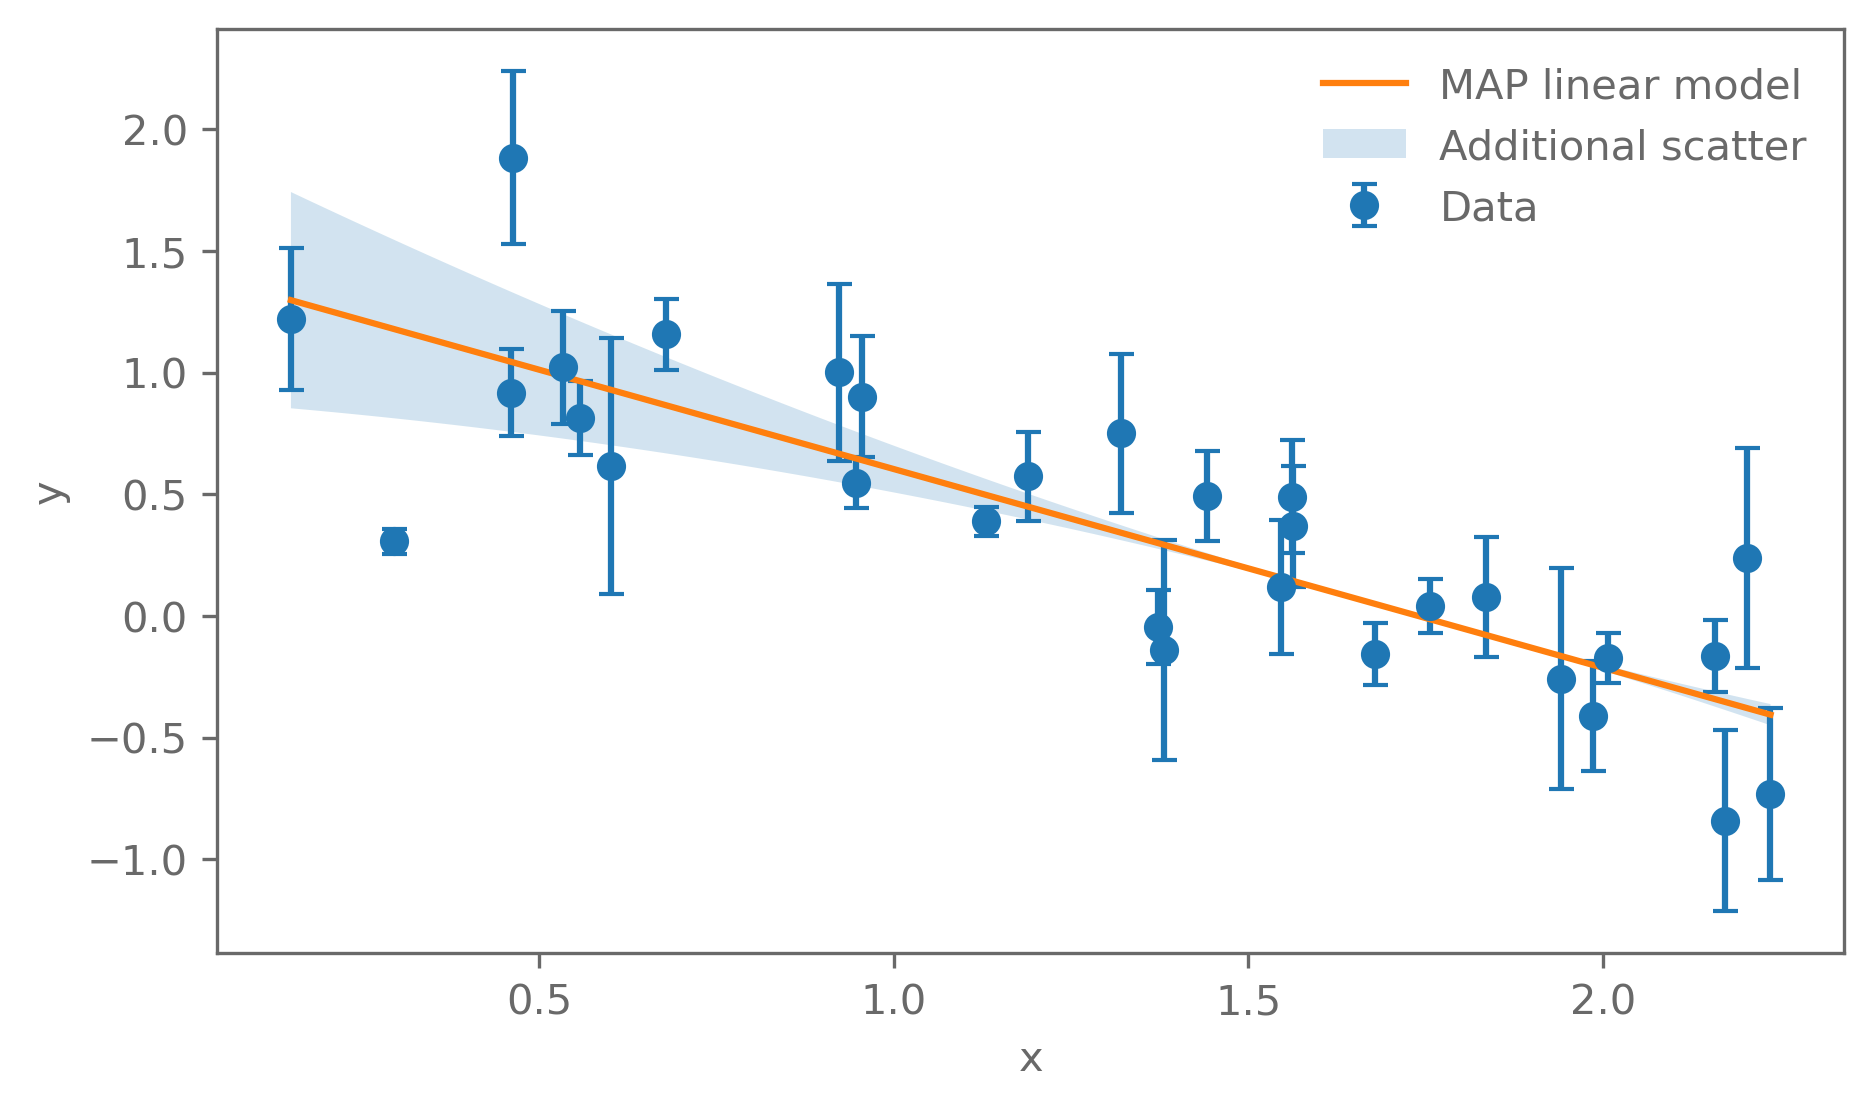

In [20]:
#Modify

from scipy.stats import halfnorm

f_prior = halfnorm(scale=1.0)

def log_likelihood_f(m, b, f, x, y, yerr):
    if f <= 0:
        return -np.inf

    mu = linear_model(x, m, b)
    sigma = yerr + f * mu**2

    return np.sum(
        -0.5 * np.log(2*np.pi)
        - np.log(sigma)
        - 0.5 * ((y - mu)/sigma)**2
    )

def log_prior_f(m, b, f):
    if f <= 0:
        return -np.inf

    return log_prior(m, b) + f_prior.logpdf(f)

def log_posterior_f(m, b, f, x, y, yerr):
    return (
        log_likelihood_f(m, b, f, x, y, yerr)
        + log_prior_f(m, b, f)
    )

from scipy.optimize import minimize

def negative_log_posterior(params):
    m, b, f = params
    return -log_posterior_f(m, b, f, x1, y1, yerr1)

result = minimize(
    negative_log_posterior,
    x0=[-1, 2, 0.5],
    bounds=[(None, None), (None, None), (1e-8, None)],
    method="L-BFGS-B"
)

if not result.success:
    print("Optimization warning:", result.message)

m_map, b_map, f_map = result.x

print("MAP slope:", m_map)
print("MAP intercept:", b_map)
print("MAP f:", f_map)

x_plot = np.linspace(min(x1), max(x1), 200)

mu_plot = linear_model(x_plot, m_map, b_map)
sigma_plot = f_map * mu_plot**2

plt.errorbar(x1, y1, yerr=yerr1,
             fmt="o", capsize=3, label="Data")

plt.plot(x_plot, mu_plot, label="MAP linear model")

plt.fill_between(
    x_plot,
    mu_plot - sigma_plot,
    mu_plot + sigma_plot,
    alpha=0.2,
    label="Additional scatter"
)

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

# Exercise 2

The data in the previous example were a synthetic version of real observations that were obtained in an AstroWoche project in 2024 by Jonas Spiller, Theo Lequy, Clara Bleich. 

<!-- ![jovian moons data](../assets/jovian_moons_raw_data.png) -->
<img style="display: block; 
    margin-left: auto;
    margin-right: auto;
    width: 60%;"
    src="../assets/jovian_moons_raw_data.png" alt="jovian moons data"/>

The real observations can be found in `data/jovian_moons/{moon}.dat`:

In [4]:
moon = "Io"

t, distance, distance_alt, distance_err = np.loadtxt(
    f"../lectures/data/jovian_moons/{moon}.dat", unpack=True)

1. Repeat the analysis with the real data set. What do you find?

There is another distance estimate provided. The difference between the distance estimates comes from different approaches to converting the measured distance between Jupiter and its moons from the number of pixels to a physical distance in km.

2. How does the analysis look when using this other distance estimate (what I call `distance_alt`)? What about the other moons?



Because there are two distance estimates that do not agree, both of which are based on reasonable approaches, this suggests that there might be a _systematic_ error in the measurements. Systematic errors are usually not random (which means they do not get smaller as you obtain more data). But we could pretend the offset between the two measurements is an estimate of an unaccounted statistical uncertainty. 

3. How does the analysis look when we assume `sigma_d**2 = distance_err**2 + (distance - distance_alt)**2`?



4. Instead of assuming that the uncertainty is underestimated by this offset, we can also model it. Does the model work better if the variance is a free parameter?
